In [1]:
# ==============================================================================
# CELL 1: Imports & Environment Setup
# ==============================================================================
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.optimize import minimize
from sklearn.model_selection import StratifiedKFold
from sklearn.isotonic import IsotonicRegression
from sklearn.ensemble import HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score, median_absolute_error,
    roc_auc_score, average_precision_score, f1_score, fbeta_score,
    precision_score, recall_score, classification_report, confusion_matrix,
    roc_curve, precision_recall_curve
)

import lightgbm as lgb

try:
    from catboost import CatBoostRegressor, CatBoostClassifier
    HAS_CATBOOST = True
except ImportError:
    HAS_CATBOOST = False

SEED = 42
np.random.seed(SEED)
sns.set_style("whitegrid")
print(f"Environment initialized | LightGBM: {lgb.__version__} | CatBoost available: {HAS_CATBOOST}")

Environment initialized | LightGBM: 4.6.0 | CatBoost available: True


In [2]:
# ==============================================================================
# CELL 2: Load Task 3 Datasets & Schema Audit
# ==============================================================================
DATA_DIR = (
    "/kaggle/input/competitions/player-intelligence-system-cpe-342-ml/cpe342-kaggle-main/03_regression"
    if os.path.exists("/kaggle/input/competitions/player-intelligence-system-cpe-342-ml/cpe342-kaggle-main/03_regression")
    else "."
)

train_df = pd.read_csv(f"{DATA_DIR}/train.csv")
test_df = pd.read_csv(f"{DATA_DIR}/test.csv")

# Encode any string/object columns consistently across train & test if present
obj_cols = [
    c for c in test_df.columns
    if c != 'player_id' and (train_df[c].dtype == 'object' or test_df[c].dtype == 'object')
]
for c in obj_cols:
    combined_cats = pd.concat([train_df[c], test_df[c]], axis=0).astype('category').cat.categories
    train_df[c] = pd.Categorical(train_df[c], categories=combined_cats).codes.astype(float)
    test_df[c] = pd.Categorical(test_df[c], categories=combined_cats).codes.astype(float)
    train_df.loc[train_df[c] < 0, c] = np.nan
    test_df.loc[test_df[c] < 0, c] = np.nan

print(f"Train Shape: {train_df.shape} | Test Shape: {test_df.shape}")
print(f"Zero-Spending Players in Train: {(train_df['spending_30d'] == 0).sum():,} "
      f"({(train_df['spending_30d'] == 0).mean()*100:.2f}%)")
print(f"Mean Spend: ฿{train_df['spending_30d'].mean():,.2f} | "
      f"Median Spend: ฿{train_df['spending_30d'].median():,.2f} | "
      f"Max Spend: ฿{train_df['spending_30d'].max():,.2f}")

Train Shape: (104000, 34) | Test Shape: (25889, 33)
Zero-Spending Players in Train: 50,049 (48.12%)
Mean Spend: ฿10,497.04 | Median Spend: ฿79.44 | Max Spend: ฿300,000.00


In [3]:
# ==============================================================================
# CELL 3: 3-Pass Exact Algebraic & Rule-Based Imputation
# ==============================================================================
def exact_algebraic_imputation(df_in):
    df = df_in.copy()
    feature_subset = [c for c in df.columns if c not in ['player_id', 'spending_30d']]

    # Granular missingness indicators before imputation
    df['missing_count'] = df[feature_subset].isna().sum(axis=1)
    df['hist_is_nan'] = df['historical_spending'].isna().astype(float)
    df['prev_is_nan'] = df['prev_month_spending'].isna().astype(float)
    df['seg_is_nan'] = df['segment'].isna().astype(float)
    df['tx_is_nan'] = df['total_transactions'].isna().astype(float)
    df['atv_is_nan'] = df['avg_transaction_value'].isna().astype(float)

    # 3-Pass Deterministic Algebraic Reconstruction (exact identities only)
    for _ in range(3):
        t1 = np.where(
            (df['avg_transaction_value'] > 0) & df['historical_spending'].notna(),
            np.round(df['historical_spending'] / df['avg_transaction_value']), np.nan
        )
        t2 = np.where(
            (df['discount_rate_used'] > 0) & df['purchases_on_discount'].notna(),
            np.round(df['purchases_on_discount'] / df['discount_rate_used']), np.nan
        )
        df['total_transactions'] = (
            df['total_transactions']
            .fillna(pd.Series(t1, index=df.index))
            .fillna(pd.Series(t2, index=df.index))
        )

        a1 = np.where(
            (df['total_transactions'] > 0) & df['historical_spending'].notna(),
            df['historical_spending'] / df['total_transactions'], np.nan
        )
        df['avg_transaction_value'] = df['avg_transaction_value'].fillna(pd.Series(a1, index=df.index))

        h1 = np.where(
            (df['total_transactions'] > 0) & df['avg_transaction_value'].notna(),
            df['total_transactions'] * df['avg_transaction_value'], np.nan
        )
        df['historical_spending'] = df['historical_spending'].fillna(pd.Series(h1, index=df.index))

        dp = np.where(
            df['total_transactions'].notna() & df['discount_rate_used'].notna(),
            np.round(df['total_transactions'] * df['discount_rate_used']), np.nan
        )
        df['purchases_on_discount'] = df['purchases_on_discount'].fillna(pd.Series(dp, index=df.index))

        dr = np.where(
            (df['total_transactions'] > 0) & df['purchases_on_discount'].notna(),
            df['purchases_on_discount'] / df['total_transactions'], np.nan
        )
        df['discount_rate_used'] = df['discount_rate_used'].fillna(pd.Series(dr, index=df.index))

    # Exact Rule: is_premium_member == 1.0 iff vip_status >= 3.0
    prem_from_vip = np.where(df['vip_status'].notna(), (df['vip_status'] >= 3.0).astype(float), np.nan)
    df['is_premium_member'] = df['is_premium_member'].fillna(pd.Series(prem_from_vip, index=df.index))

    vip_from_prem = np.where(
        df['is_premium_member'] == 1.0, 3.0,
        np.where(df['is_premium_member'] == 0.0, 0.0, np.nan)
    )
    df['vip_status_imputed'] = df['vip_status'].fillna(pd.Series(vip_from_prem, index=df.index))

    # Relation: cross_game_activity median ~= 8.0 * games_played
    games_from_cross = np.where(
        df['cross_game_activity'].notna(),
        np.clip(np.round(df['cross_game_activity'] / 8.0), 1.0, 5.0), np.nan
    )
    df['games_played_imputed'] = df['games_played'].fillna(pd.Series(games_from_cross, index=df.index))

    return df

train_fe = exact_algebraic_imputation(train_df)
test_fe = exact_algebraic_imputation(test_df)
print(f"After exact algebra -> Missing hist_spend: Train={train_fe['historical_spending'].isna().sum()}, "
      f"Test={test_fe['historical_spending'].isna().sum()}")

After exact algebra -> Missing hist_spend: Train=438, Test=112


In [4]:
# ==============================================================================
# CELL 4: Out-of-Fold ML Imputation for `segment` & Leak-Free Monetary Fallbacks
# ==============================================================================
seg_feature_cols = [c for c in train_fe.columns if c not in ['player_id', 'spending_30d', 'segment']]

for s_i in range(4):
    train_fe[f'seg_prob_{s_i}'] = np.nan
    test_fe[f'seg_prob_{s_i}'] = 0.0

known_seg_mask = train_fe['segment'].notna()
X_known = train_fe.loc[known_seg_mask, seg_feature_cols]
y_known = train_fe.loc[known_seg_mask, 'segment'].astype(int)

skf_seg = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
oof_seg_probs = np.zeros((len(X_known), 4))
nan_seg_probs = np.zeros(((~known_seg_mask).sum(), 4))
test_seg_probs = np.zeros((len(test_fe), 4))

for fold_s, (tr_i, va_i) in enumerate(skf_seg.split(X_known, y_known)):
    clf_s = lgb.LGBMClassifier(
        n_estimators=800, learning_rate=0.04, num_leaves=63,
        colsample_bytree=0.8, subsample=0.8, random_state=SEED + fold_s, n_jobs=-1, verbose=-1
    )
    clf_s.fit(
        X_known.iloc[tr_i], y_known.iloc[tr_i],
        eval_set=[(X_known.iloc[va_i], y_known.iloc[va_i])],
        callbacks=[lgb.early_stopping(50, verbose=False)]
    )
    oof_seg_probs[va_i] = clf_s.predict_proba(X_known.iloc[va_i])
    nan_seg_probs += clf_s.predict_proba(train_fe.loc[~known_seg_mask, seg_feature_cols]) / 5.0
    test_seg_probs += clf_s.predict_proba(test_fe[seg_feature_cols]) / 5.0

for s_i in range(4):
    train_fe.loc[known_seg_mask, f'seg_prob_{s_i}'] = oof_seg_probs[:, s_i]
    train_fe.loc[~known_seg_mask, f'seg_prob_{s_i}'] = nan_seg_probs[:, s_i]
    test_fe[f'seg_prob_{s_i}'] = test_seg_probs[:, s_i]

train_fe['segment_imputed'] = train_fe['segment'].fillna(
    pd.Series(np.argmax(nan_seg_probs, axis=1).astype(float), index=train_fe.index[~known_seg_mask])
)
test_fe['segment_imputed'] = test_fe['segment'].fillna(
    pd.Series(np.argmax(test_seg_probs, axis=1).astype(float), index=test_fe.index)
)

# Segment-aware prev/hist ratio imputation (learned from known train rows only)
both_present = train_fe['historical_spending'].notna() & train_fe['prev_month_spending'].notna() & (train_fe['historical_spending'] > 0)
seg_ratio_map = (
    (train_fe.loc[both_present, 'prev_month_spending'] / train_fe.loc[both_present, 'historical_spending'])
    .groupby(train_fe.loc[both_present, 'segment_imputed'])
    .median()
    .to_dict()
)
seg_hist_medians = train_fe.groupby('segment_imputed')['historical_spending'].median().to_dict()

for df_tmp in [train_fe, test_fe]:
    seg_ratio = df_tmp['segment_imputed'].map(seg_ratio_map).fillna(0.350082)
    df_tmp['historical_spending'] = (
        df_tmp['historical_spending']
        .fillna(df_tmp['prev_month_spending'] / np.maximum(seg_ratio, 0.05))
        .fillna(df_tmp['segment_imputed'].map(seg_hist_medians))
    )
    df_tmp['prev_month_spending'] = df_tmp['prev_month_spending'].fillna(df_tmp['historical_spending'] * seg_ratio)

seg_acc = (np.argmax(oof_seg_probs, axis=1) == y_known.values).mean()
print(f"Segment Imputation OOF Accuracy: {seg_acc*100:.2f}% | Remaining NaNs: {train_fe['segment_imputed'].isna().sum()}")

Segment Imputation OOF Accuracy: 92.33% | Remaining NaNs: 0


In [5]:
# ==============================================================================
# CELL 5: Domain-Specific Monetary, RFM-T Momentum & Game-LTV Feature Engineering
# ==============================================================================
def add_domain_features(df_in):
    df = df_in.copy()
    eps = 1e-5

    # 1. Seasonal multiplier flags (Months 0,11 = Peak 1.25x | Months 5,6 = Mid 1.15x)
    df['is_peak_season'] = df['seasonal_spending_pattern'].isin([0.0, 11.0]).astype(float)
    df['is_mid_season'] = df['seasonal_spending_pattern'].isin([5.0, 6.0]).astype(float)
    season_mult = 1.0 + 0.25 * df['is_peak_season'] + 0.15 * df['is_mid_season']

    # 2. Core monetary ratios & log transforms
    df['spend_ratio_prev_hist'] = df['prev_month_spending'] / (df['historical_spending'] + eps)
    df['spend_diff_prev_expected'] = df['prev_month_spending'] - (0.350082 * df['historical_spending'])
    df['log_historical_spending'] = np.log1p(np.maximum(0, df['historical_spending']))
    df['log_prev_month_spending'] = np.log1p(np.maximum(0, df['prev_month_spending']))
    df['log_avg_transaction_value'] = np.log1p(np.maximum(0, df['avg_transaction_value'].fillna(0)))
    df['monthly_historical_burn'] = df['historical_spending'] / ((df['account_age_days'] / 30.0) + 1.0)
    df['seasonal_adjusted_prev_spend'] = df['prev_month_spending'] * season_mult
    df['seasonal_adjusted_burn'] = df['monthly_historical_burn'] * season_mult

    # 3. RFM-T Spending Acceleration & Inter-Purchase Overdue Signals
    df['spend_acceleration'] = df['prev_month_spending'] / (df['monthly_historical_burn'] + 1.0)
    df['expected_interpurchase_days'] = df['account_age_days'] / (df['total_transactions'].fillna(0) + 1.0)
    df['purchase_overdue_ratio'] = df['days_since_last_purchase'] / (df['expected_interpurchase_days'] + 1.0)
    df['implied_hist_freq'] = df['total_transactions'].fillna(0) / ((df['account_age_days'] / 30.0) + 1.0)
    df['freq_momentum'] = df['purchase_frequency'] - df['implied_hist_freq']

    # 4. Recency, cadence & discount elasticity
    df['purchase_recency_ratio'] = df['days_since_last_purchase'] / (df['account_age_days'] + 1.0)
    df['days_plus_3freq'] = df['days_since_last_purchase'] + 3.0 * df['purchase_frequency']
    df['days_x_freq'] = df['days_since_last_purchase'] * df['purchase_frequency']
    df['full_price_transactions'] = df['total_transactions'] - df['purchases_on_discount']
    df['full_price_spend_est'] = df['full_price_transactions'] * df['avg_transaction_value']
    df['discount_season_boost'] = df['discount_rate_used'].fillna(0) * season_mult

    # 5. Playtime-to-Spend Conversion Efficiency & VIP/Cross-Game Spillover
    df['cross_per_game'] = df['cross_game_activity'] / (df['games_played_imputed'] + eps)
    df['cross_game_residual'] = df['cross_game_activity'] - (8.0 * df['games_played_imputed'])
    df['cross_game_wallet_proxy'] = df['cross_game_activity'] * df['log_prev_month_spending']
    df['weekly_playtime_hours'] = (df['sessions_per_week'] * df['avg_session_length']) / 60.0
    df['lifetime_play_hours'] = df['weekly_playtime_hours'] * (df['account_age_days'] / 7.0)
    df['spend_per_session'] = df['prev_month_spending'] / (df['sessions_per_week'] * 4.33 + 1.0)
    df['tx_conversion_rate'] = df['purchase_frequency'] / (df['sessions_per_week'] + 0.1)
    df['spend_per_play_hour'] = df['historical_spending'] / (df['lifetime_play_hours'] + 1.0)
    df['vip_distance_to_premium'] = 3.0 - df['vip_status_imputed'].fillna(0)

    # 6. Segment & VIP multiplicative spending proxies
    df['segment_x_hist'] = (df['segment_imputed'] + 1.0) * df['historical_spending']
    df['segment_x_prev'] = (df['segment_imputed'] + 1.0) * df['prev_month_spending']
    df['vip_x_hist'] = (df['vip_status_imputed'].fillna(0) + 1.0) * df['historical_spending']
    df['expected_seg_mult'] = (
        0.416 * df['seg_prob_0'] + 0.675 * df['seg_prob_1'] +
        0.808 * df['seg_prob_2'] + 1.652 * df['seg_prob_3']
    ) * df['historical_spending']

    return df

train_fe = add_domain_features(train_fe)
test_fe = add_domain_features(test_fe)

# Peer-group relative ranking features (computed from feature distributions only)
combined_all = pd.concat([train_fe.drop(columns=['spending_30d']), test_fe], axis=0)
grp_cols = ['segment_imputed', 'vip_status_imputed', 'seasonal_spending_pattern']
grp_stats = combined_all.groupby(grp_cols, dropna=False).agg(
    grp_prev_med=('prev_month_spending', 'median'),
    grp_hist_med=('historical_spending', 'median'),
    grp_sess_mean=('sessions_per_week', 'mean')
).reset_index()

train_fe = train_fe.merge(grp_stats, on=grp_cols, how='left')
test_fe = test_fe.merge(grp_stats, on=grp_cols, how='left')

for df_tmp in [train_fe, test_fe]:
    df_tmp['prev_vs_grp_med'] = df_tmp['prev_month_spending'] / (df_tmp['grp_prev_med'] + 1.0)
    df_tmp['hist_vs_grp_med'] = df_tmp['historical_spending'] / (df_tmp['grp_hist_med'] + 1.0)
    df_tmp['sess_vs_grp_mean'] = df_tmp['sessions_per_week'] - df_tmp['grp_sess_mean']

feature_cols = [c for c in train_fe.columns if c not in ['player_id', 'spending_30d']]
print(f"Total Engineered Features Ready for Training: {len(feature_cols)}")

Total Engineered Features Ready for Training: 85


In [6]:
# ==============================================================================
# CELL 6: 5-Fold Stratified CV — Multi-Quantile, Calibrated Hurdle & Diverse Models
# ==============================================================================
X = train_fe[feature_cols].copy()
y = train_fe['spending_30d'].values
y_is_pos = (y > 0).astype(int)
test_X = test_fe[feature_cols].copy()

# Unified categorical dtypes for native GBDT categorical splits
cat_cols = ['segment_imputed', 'seasonal_spending_pattern', 'vip_status_imputed']
for col in cat_cols:
    cats = pd.concat([X[col], test_X[col]], axis=0).astype('category').cat.categories
    X[col] = pd.Categorical(X[col], categories=cats)
    test_X[col] = pd.Categorical(test_X[col], categories=cats)

strat_key = y_is_pos.astype(str) + "_" + train_fe['segment_imputed'].astype(int).astype(str)
N_FOLDS = 5
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

QUANTILES = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]
oof_quantiles = np.zeros((len(train_fe), len(QUANTILES)))
test_quantiles = np.zeros((len(test_fe), len(QUANTILES)))

oof_prob_raw = np.zeros(len(train_fe))
test_prob_raw = np.zeros(len(test_fe))
oof_prob_cal = np.zeros(len(train_fe))
test_prob_cal = np.zeros(len(test_fe))

# Ordinal exceedance probabilities: P(y > 1k) and P(y > 25k)
oof_prob_1k = np.zeros(len(train_fe))
test_prob_1k = np.zeros(len(test_fe))
oof_prob_25k = np.zeros(len(train_fe))
test_prob_25k = np.zeros(len(test_fe))

# Diverse continuous predictors
oof_reg_all = np.zeros(len(train_fe))
test_reg_all = np.zeros(len(test_fe))
oof_med_via_hist = np.zeros(len(train_fe))
test_med_via_hist = np.zeros(len(test_fe))
oof_med_via_prev = np.zeros(len(train_fe))
test_med_via_prev = np.zeros(len(test_fe))
oof_tweedie = np.zeros(len(train_fe))
test_tweedie = np.zeros(len(test_fe))
oof_whale_spec = np.zeros(len(train_fe))
test_whale_spec = np.zeros(len(test_fe))

fold_assignments = np.zeros(len(train_fe), dtype=int)

for fold, (train_idx, val_idx) in enumerate(skf.split(X, strat_key)):
    fold_assignments[val_idx] = fold + 1
    X_tr, y_tr, pos_tr = X.iloc[train_idx], y[train_idx], y_is_pos[train_idx]
    X_va, y_va, pos_va = X.iloc[val_idx], y[val_idx], y_is_pos[val_idx]

    # --------------------------------------------------------------------------
    # 1. Stage-1 Hurdle Classifier Ensemble + Out-of-Fold Isotonic Calibration
    # --------------------------------------------------------------------------
    clf_lgb = lgb.LGBMClassifier(
        n_estimators=2500, learning_rate=0.025, num_leaves=63,
        min_child_samples=30, colsample_bytree=0.8, subsample=0.8, subsample_freq=1,
        reg_alpha=1.0, reg_lambda=2.0, random_state=SEED + fold, n_jobs=-1, verbose=-1
    )
    clf_lgb.fit(
        X_tr, pos_tr, eval_set=[(X_va, pos_va)],
        callbacks=[lgb.early_stopping(100, verbose=False)]
    )
    p_va_lgb = clf_lgb.predict_proba(X_va)[:, 1]
    p_te_lgb = clf_lgb.predict_proba(test_X)[:, 1]

    clf_hgb = HistGradientBoostingClassifier(
        max_iter=500, learning_rate=0.03, max_leaf_nodes=63,
        min_samples_leaf=30, l2_regularization=2.0, categorical_features=cat_cols,
        random_state=SEED + fold
    )
    clf_hgb.fit(X_tr, pos_tr)
    p_va_hgb = clf_hgb.predict_proba(X_va)[:, 1]
    p_te_hgb = clf_hgb.predict_proba(test_X)[:, 1]

    raw_va = 0.65 * p_va_lgb + 0.35 * p_va_hgb
    raw_te = 0.65 * p_te_lgb + 0.35 * p_te_hgb
    oof_prob_raw[val_idx] = raw_va
    test_prob_raw += raw_te / N_FOLDS

    iso = IsotonicRegression(out_of_bounds='clip')
    oof_prob_cal[val_idx] = iso.fit_transform(raw_va, pos_va)
    test_prob_cal += iso.transform(raw_te) / N_FOLDS

    # --------------------------------------------------------------------------
    # 2. Ordinal Exceedance Classifiers: P(y > 1,000) & P(y > 25,000)
    # --------------------------------------------------------------------------
    for thresh, oof_arr, test_arr in [
        (1000.0, oof_prob_1k, test_prob_1k),
        (25000.0, oof_prob_25k, test_prob_25k)
    ]:
        clf_ord = lgb.LGBMClassifier(
            n_estimators=2000, learning_rate=0.03, num_leaves=63,
            colsample_bytree=0.8, subsample=0.8, random_state=SEED + fold, n_jobs=-1, verbose=-1
        )
        clf_ord.fit(
            X_tr, (y_tr > thresh).astype(int),
            eval_set=[(X_va, (y_va > thresh).astype(int))],
            callbacks=[lgb.early_stopping(80, verbose=False)]
        )
        oof_arr[val_idx] = clf_ord.predict_proba(X_va)[:, 1]
        test_arr += clf_ord.predict_proba(test_X)[:, 1] / N_FOLDS

    # --------------------------------------------------------------------------
    # 3. Direct L1 Regressor Ensemble on All Players
    # --------------------------------------------------------------------------
    reg_lgb = lgb.LGBMRegressor(
        objective='regression_l1', n_estimators=3000, learning_rate=0.025, num_leaves=63,
        min_child_samples=25, colsample_bytree=0.8, subsample=0.8, subsample_freq=1,
        reg_alpha=1.0, reg_lambda=2.0, random_state=SEED + fold, n_jobs=-1, verbose=-1
    )
    reg_lgb.fit(
        X_tr, y_tr, eval_set=[(X_va, y_va)],
        callbacks=[lgb.early_stopping(100, verbose=False)]
    )
    pred_va_lgb = np.maximum(0.0, reg_lgb.predict(X_va))
    pred_te_lgb = np.maximum(0.0, reg_lgb.predict(test_X))

    if HAS_CATBOOST:
        X_tr_cb, X_va_cb, test_X_cb = X_tr.copy(), X_va.copy(), test_X.copy()
        for c in cat_cols:
            X_tr_cb[c] = X_tr_cb[c].cat.codes.astype(int)
            X_va_cb[c] = X_va_cb[c].cat.codes.astype(int)
            test_X_cb[c] = test_X_cb[c].cat.codes.astype(int)
        reg_cb = CatBoostRegressor(
            loss_function='MAE', iterations=3000, learning_rate=0.04, depth=7,
            cat_features=cat_cols, random_seed=SEED + fold, verbose=0
        )
        reg_cb.fit(X_tr_cb, y_tr, eval_set=(X_va_cb, y_va), early_stopping_rounds=100, verbose=False)
        pred_va_2 = np.maximum(0.0, reg_cb.predict(X_va_cb))
        pred_te_2 = np.maximum(0.0, reg_cb.predict(test_X_cb))
    else:
        reg_hgb = HistGradientBoostingRegressor(
            loss='absolute_error', max_iter=600, learning_rate=0.03, max_leaf_nodes=63,
            min_samples_leaf=25, l2_regularization=2.0, categorical_features=cat_cols,
            random_state=SEED + fold
        )
        reg_hgb.fit(X_tr, y_tr)
        pred_va_2 = np.maximum(0.0, reg_hgb.predict(X_va))
        pred_te_2 = np.maximum(0.0, reg_hgb.predict(test_X))

    oof_reg_all[val_idx] = 0.60 * pred_va_lgb + 0.40 * pred_va_2
    test_reg_all += (0.60 * pred_te_lgb + 0.40 * pred_te_2) / N_FOLDS

    # --------------------------------------------------------------------------
    # 4. Tweedie Zero-Inflated Regressor on All Players
    # --------------------------------------------------------------------------
    reg_tw = lgb.LGBMRegressor(
        objective='tweedie', tweedie_variance_power=1.35,
        n_estimators=2500, learning_rate=0.025, num_leaves=63,
        min_child_samples=30, colsample_bytree=0.8, subsample=0.8, subsample_freq=1,
        random_state=SEED + fold, n_jobs=-1, verbose=-1
    )
    reg_tw.fit(
        X_tr, y_tr, eval_set=[(X_va, y_va)],
        callbacks=[lgb.early_stopping(100, verbose=False)]
    )
    oof_tweedie[val_idx] = np.maximum(0.0, reg_tw.predict(X_va))
    test_tweedie += np.maximum(0.0, reg_tw.predict(test_X)) / N_FOLDS

    # --------------------------------------------------------------------------
    # 5. Conditional Models on ALL Active Spenders (y_tr > 0 — No Ratio Clipping!)
    # --------------------------------------------------------------------------
    pos_mask_tr = y_tr > 0
    pos_mask_va = y_va > 0
    X_tr_pos, y_tr_pos = X_tr.loc[pos_mask_tr], y_tr[pos_mask_tr]
    X_va_pos, y_va_pos = X_va.loc[pos_mask_va], y_va[pos_mask_va]

    # 5A. Direct Non-Parametric Multi-Quantile Regressors (alpha = 0.10 .. 0.90)
    for q_idx, q in enumerate(QUANTILES):
        q_reg = lgb.LGBMRegressor(
            objective='quantile', alpha=q,
            n_estimators=2500, learning_rate=0.03, num_leaves=63,
            min_child_samples=25, colsample_bytree=0.8, subsample=0.8, subsample_freq=1,
            reg_alpha=1.0, reg_lambda=2.0, random_state=SEED + fold + q_idx * 10, n_jobs=-1, verbose=-1
        )
        q_reg.fit(
            X_tr_pos, y_tr_pos, eval_set=[(X_va_pos, y_va_pos)],
            callbacks=[lgb.early_stopping(100, verbose=False)]
        )
        oof_quantiles[val_idx, q_idx] = np.maximum(0.0, q_reg.predict(X_va))
        test_quantiles[:, q_idx] += np.maximum(0.0, q_reg.predict(test_X)) / N_FOLDS

    # 5B. Multiplicative Ratio L1 Model A: log(y / historical_spending) on ALL y > 0
    valid_h_tr = pos_mask_tr & (X_tr['historical_spending'].values > 1.0)
    valid_h_va = pos_mask_va & (X_va['historical_spending'].values > 1.0)
    m_rh = lgb.LGBMRegressor(
        objective='regression_l1', n_estimators=2500, learning_rate=0.025, num_leaves=63,
        min_child_samples=20, colsample_bytree=0.8, subsample=0.8, subsample_freq=1,
        random_state=SEED + fold, n_jobs=-1, verbose=-1
    )
    m_rh.fit(
        X_tr.loc[valid_h_tr], np.log(y_tr[valid_h_tr] / X_tr.loc[valid_h_tr, 'historical_spending'].values),
        eval_set=[(X_va.loc[valid_h_va], np.log(y_va[valid_h_va] / X_va.loc[valid_h_va, 'historical_spending'].values))],
        callbacks=[lgb.early_stopping(100, verbose=False)]
    )
    oof_med_via_hist[val_idx] = np.exp(m_rh.predict(X_va)) * X_va['historical_spending'].values
    test_med_via_hist += (np.exp(m_rh.predict(test_X)) * test_X['historical_spending'].values) / N_FOLDS

    # 5C. Multiplicative Ratio L1 Model B: log(y / prev_month_spending) on ALL y > 0
    valid_p_tr = pos_mask_tr & (X_tr['prev_month_spending'].values > 1.0)
    valid_p_va = pos_mask_va & (X_va['prev_month_spending'].values > 1.0)
    m_rp = lgb.LGBMRegressor(
        objective='regression_l1', n_estimators=2500, learning_rate=0.025, num_leaves=63,
        min_child_samples=20, colsample_bytree=0.8, subsample=0.8, subsample_freq=1,
        random_state=SEED + 100 + fold, n_jobs=-1, verbose=-1
    )
    m_rp.fit(
        X_tr.loc[valid_p_tr], np.log(y_tr[valid_p_tr] / X_tr.loc[valid_p_tr, 'prev_month_spending'].values),
        eval_set=[(X_va.loc[valid_p_va], np.log(y_va[valid_p_va] / X_va.loc[valid_p_va, 'prev_month_spending'].values))],
        callbacks=[lgb.early_stopping(100, verbose=False)]
    )
    oof_med_via_prev[val_idx] = np.exp(m_rp.predict(X_va)) * X_va['prev_month_spending'].values
    test_med_via_prev += (np.exp(m_rp.predict(test_X)) * test_X['prev_month_spending'].values) / N_FOLDS

    # --------------------------------------------------------------------------
    # 6. Dedicated Segment 3 (Whale) Specialist Model
    # --------------------------------------------------------------------------
    seg3_tr = (train_fe.iloc[train_idx]['segment_imputed'].values == 3.0)
    seg3_va = (train_fe.iloc[val_idx]['segment_imputed'].values == 3.0)
    seg3_te = (test_fe['segment_imputed'].values == 3.0)

    reg_whale = lgb.LGBMRegressor(
        objective='regression_l1', n_estimators=2500, learning_rate=0.02, num_leaves=45,
        min_child_samples=20, colsample_bytree=0.75, subsample=0.8, subsample_freq=1,
        reg_alpha=2.0, reg_lambda=5.0, random_state=SEED + 300 + fold, n_jobs=-1, verbose=-1
    )
    reg_whale.fit(
        X_tr.loc[seg3_tr], y_tr[seg3_tr],
        eval_set=[(X_va.loc[seg3_va], y_va[seg3_va])],
        callbacks=[lgb.early_stopping(100, verbose=False)]
    )
    oof_whale_spec[val_idx[seg3_va]] = np.maximum(0.0, reg_whale.predict(X_va.loc[seg3_va]))
    test_whale_spec[seg3_te] += np.maximum(0.0, reg_whale.predict(test_X.loc[seg3_te])) / N_FOLDS

    print(f"Fold {fold+1}/{N_FOLDS} | Cal Clf AUC: {roc_auc_score(pos_va, oof_prob_cal[val_idx]):.4f} | "
          f"Direct L1 MAE: {mean_absolute_error(y_va, oof_reg_all[val_idx]):,.2f} THB | "
          f"Seg3 Whale MAE: {mean_absolute_error(y_va[seg3_va], oof_whale_spec[val_idx[seg3_va]]):,.2f} THB")

# Enforce non-crossing monotonicity across predicted quantiles
oof_quantiles = np.sort(oof_quantiles, axis=1)
test_quantiles = np.sort(test_quantiles, axis=1)

Fold 1/5 | Cal Clf AUC: 0.7853 | Direct L1 MAE: 2,729.49 THB | Seg3 Whale MAE: 15,260.49 THB
Fold 2/5 | Cal Clf AUC: 0.7877 | Direct L1 MAE: 2,832.13 THB | Seg3 Whale MAE: 16,193.44 THB
Fold 3/5 | Cal Clf AUC: 0.7860 | Direct L1 MAE: 2,762.51 THB | Seg3 Whale MAE: 15,629.59 THB
Fold 4/5 | Cal Clf AUC: 0.7856 | Direct L1 MAE: 2,746.80 THB | Seg3 Whale MAE: 15,411.17 THB
Fold 5/5 | Cal Clf AUC: 0.7867 | Direct L1 MAE: 2,806.88 THB | Seg3 Whale MAE: 15,907.58 THB


In [7]:
# ==============================================================================
# CELL 7 (FAST UPGRADE): Heteroscedastic Quantile Tail + Convex Nested Blend
# ==============================================================================
from scipy.stats import norm

Q_GRID = np.array(QUANTILES, dtype=float)
Z_10 = abs(norm.ppf(0.10))  # ~1.28155
Z_90 = abs(norm.ppf(0.90))  # ~1.28155

def heteroscedastic_quantile_interp(tau, q_preds, q_grid=Q_GRID):
    """
    Interpolates inside [0.10, 0.90] and extrapolates smoothly into (0, 0.10)
    and (0.90, 1.0) using each player's own predicted local log-spread.
    """
    n = len(tau)
    out = np.zeros(n)
    
    # Interior [0.10, 0.90]
    mid = (tau >= q_grid[0]) & (tau <= q_grid[-1])
    if mid.any():
        t_mid = tau[mid]
        idx = np.clip(np.searchsorted(q_grid, t_mid, side='right') - 1, 0, len(q_grid) - 2)
        q_lo = q_grid[idx]
        q_hi = q_grid[idx + 1]
        w = (t_mid - q_lo) / (q_hi - q_lo)
        rows = np.where(mid)[0]
        out[mid] = q_preds[rows, idx] * (1.0 - w) + q_preds[rows, idx + 1] * w

    # Left tail (0, 0.10): player-specific log-normal decay anchored at Q10 & Q50
    low = tau < q_grid[0]
    if low.any():
        q10 = np.maximum(q_preds[low, 0], 1e-3)
        q50 = np.maximum(q_preds[low, 4], q10)
        sigma_lo = np.clip(np.log(q50 / q10) / Z_10, 0.05, 1.50)
        z_tau = norm.ppf(np.clip(tau[low], 1e-4, 0.0999))
        out[low] = q50 * np.exp(sigma_lo * z_tau)

    # Right tail (0.90, 1.0): player-specific upper tail anchored at Q50 & Q90
    high = tau > q_grid[-1]
    if high.any():
        q50 = np.maximum(q_preds[high, 4], 1e-3)
        q90 = np.maximum(q_preds[high, -1], q50)
        sigma_hi = np.clip(np.log(q90 / q50) / Z_90, 0.05, 1.20)
        z_tau = norm.ppf(np.clip(tau[high], 0.9001, 0.9995))
        out[high] = q50 * np.exp(sigma_hi * z_tau)

    return out

def build_candidate_matrix(prob, q_preds, r_all, m_hist, m_prev, r_tw, r_whale, p_25k, tau_shift=0.0):
    safe_p = np.clip(prob, 0.500001, 0.999999)
    tau_star = np.clip(1.0 - 1.0 / (2.0 * safe_p) + tau_shift, 1e-4, 0.9995)
    q_cond = heteroscedastic_quantile_interp(tau_star, q_preds)
    
    # Ordinal-gated whale specialist
    whale_gated = p_25k * r_whale + (1.0 - p_25k) * r_all
    return np.column_stack([q_cond, r_all, m_hist, m_prev, r_tw, r_whale, whale_gated])

oof_nonparam_only = np.zeros(len(train_fe))
oof_final = np.zeros(len(train_fe))
test_final = np.zeros(len(test_fe))

# Baseline check: pure heteroscedastic quantile hurdle at p > 0.50
for seg in [0.0, 1.0, 2.0, 3.0]:
    tr_m = (train_fe['segment_imputed'] == seg).values
    X_cand = build_candidate_matrix(
        oof_prob_cal[tr_m], oof_quantiles[tr_m], oof_reg_all[tr_m],
        oof_med_via_hist[tr_m], oof_med_via_prev[tr_m], oof_tweedie[tr_m],
        oof_whale_spec[tr_m], oof_prob_25k[tr_m], tau_shift=0.0
    )
    oof_nonparam_only[tr_m] = np.where(oof_prob_cal[tr_m] <= 0.50, 0.0, X_cand[:, 0])

# Nested Out-of-Fold optimization with exact 1D p_cutoff grid + convex weight solver
CUTOFF_GRID = np.linspace(0.46, 0.55, 19)
TAU_SHIFT_GRID = [-0.03, -0.015, 0.0, 0.015, 0.03]

for seg in [0.0, 1.0, 2.0, 3.0]:
    is_seg3 = (seg == 3.0)
    n_models = 7 if is_seg3 else 5
    w_bounds = [(0.0, 1.5)] * n_models
    
    tr_seg_mask = (train_fe['segment_imputed'] == seg).values
    te_seg_mask = (test_fe['segment_imputed'] == seg).values
    fold_configs = []

    for f in range(1, N_FOLDS + 1):
        in_tr = tr_seg_mask & (fold_assignments != f)
        in_va = tr_seg_mask & (fold_assignments == f)
        y_tr_s = y[in_tr]
        p_tr_s = oof_prob_cal[in_tr]

        best_loss = np.inf
        best_cfg = None

        for t_shift in TAU_SHIFT_GRID:
            M_tr = build_candidate_matrix(
                p_tr_s, oof_quantiles[in_tr], oof_reg_all[in_tr],
                oof_med_via_hist[in_tr], oof_med_via_prev[in_tr], oof_tweedie[in_tr],
                oof_whale_spec[in_tr], oof_prob_25k[in_tr], tau_shift=t_shift
            )[:, :n_models]

            for c_val in CUTOFF_GRID:
                act = p_tr_s > c_val
                zero_err = y_tr_s[~act].sum()
                if zero_err >= best_loss:
                    continue

                M_act = M_tr[act]
                y_act = y_tr_s[act]
                init_w = np.array([0.45, 0.15, 0.15, 0.15, 0.05, 0.15, 0.15][:n_models])

                res = minimize(
                    lambda w: np.sum(np.abs(y_act - np.clip(M_act @ w, 0.0, 300000.0))),
                    init_w, method='L-BFGS-B', bounds=w_bounds, options={'maxiter': 200}
                )
                tot_mae = (zero_err + res.fun) / len(y_tr_s)
                if tot_mae < best_loss:
                    best_loss = tot_mae
                    best_cfg = (c_val, t_shift, res.x)

        fold_configs.append(best_cfg)
        c_opt, t_opt, w_opt = best_cfg
        M_va = build_candidate_matrix(
            oof_prob_cal[in_va], oof_quantiles[in_va], oof_reg_all[in_va],
            oof_med_via_hist[in_va], oof_med_via_prev[in_va], oof_tweedie[in_va],
            oof_whale_spec[in_va], oof_prob_25k[in_va], tau_shift=t_opt
        )[:, :n_models]
        oof_final[in_va] = np.where(oof_prob_cal[in_va] <= c_opt, 0.0, np.clip(M_va @ w_opt, 0.0, 300000.0))

    # Average fold predictions on test set
    te_preds_seg = np.zeros(te_seg_mask.sum())
    for c_opt, t_opt, w_opt in fold_configs:
        M_te = build_candidate_matrix(
            test_prob_cal[te_seg_mask], test_quantiles[te_seg_mask], test_reg_all[te_seg_mask],
            test_med_via_hist[te_seg_mask], test_med_via_prev[te_seg_mask], test_tweedie[te_seg_mask],
            test_whale_spec[te_seg_mask], test_prob_25k[te_seg_mask], tau_shift=t_opt
        )[:, :n_models]
        te_preds_seg += np.where(test_prob_cal[te_seg_mask] <= c_opt, 0.0, np.clip(M_te @ w_opt, 0.0, 300000.0)) / N_FOLDS
    test_final[te_seg_mask] = te_preds_seg

print(f"Upgraded Leak-Free OOF MAE: {mean_absolute_error(y, oof_final):,.2f} THB | "
      f"NMAE: {mean_absolute_error(y, oof_final) / np.mean(y):.4f}")

Upgraded Leak-Free OOF MAE: 2,715.40 THB | NMAE: 0.2587


In [8]:
# ==============================================================================
# CELL 8: VALIDATION PART 1 — Continuous Regression & NMAE Metrics
# ==============================================================================
def evaluate_regression_suite(y_true, y_pred, model_name):
    mae = mean_absolute_error(y_true, y_pred)
    nmae_mean = mae / np.mean(y_true)
    nmae_range = mae / (np.max(y_true) - np.min(y_true))
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    med_ae = median_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    denom = (np.abs(y_true) + np.abs(y_pred)) / 2.0
    smape = np.mean(np.where(denom == 0, 0.0, np.abs(y_true - y_pred) / denom)) * 100

    return {
        "Model": model_name,
        "MAE (THB)": mae,
        "NMAE (MAE/Mean)": nmae_mean,
        "NMAE (MAE/Range)": nmae_range,
        "RMSE (THB)": rmse,
        "Median AE": med_ae,
        "R2 Score": r2,
        "SMAPE (%)": smape
    }

naive_pred = np.full_like(y, np.median(y))
raw_mult_pred = 0.5 * oof_med_via_hist + 0.5 * oof_med_via_prev

reg_results = pd.DataFrame([
    evaluate_regression_suite(y, naive_pred, "0. Naive Median Baseline"),
    evaluate_regression_suite(y, oof_reg_all, "1. Direct L1 Ensemble (All Players)"),
    evaluate_regression_suite(y, raw_mult_pred, "2. Multiplicative Ratio (Unclipped)"),
    evaluate_regression_suite(y, oof_nonparam_only, "3. Non-Parametric Quantile Hurdle"),
    evaluate_regression_suite(y, oof_final, "4. Final Nested Multi-Quantile Ensemble")
])

print("=== REGRESSION & COMPETITION METRIC VALIDATION (LEAK-FREE 5-FOLD OOF) ===")
print(reg_results.to_string(index=False, float_format=lambda x: f"{x:,.4f}"))

=== REGRESSION & COMPETITION METRIC VALIDATION (LEAK-FREE 5-FOLD OOF) ===
                                  Model   MAE (THB)  NMAE (MAE/Mean)  NMAE (MAE/Range)  RMSE (THB)  Median AE  R2 Score  SMAPE (%)
               0. Naive Median Baseline 10,495.4776           0.9999            0.0350 32,295.1842    79.4350   -0.1161   182.4728
    1. Direct L1 Ensemble (All Players)  2,775.5641           0.2644            0.0093 13,059.0598   247.0660    0.8175   123.9923
    2. Multiplicative Ratio (Unclipped)  2,811.1407           0.2678            0.0094 13,013.7124   313.4131    0.8188   103.1349
      3. Non-Parametric Quantile Hurdle  2,764.3922           0.2633            0.0092 13,061.5526   204.8344    0.8174    62.0157
4. Final Nested Multi-Quantile Ensemble  2,715.4042           0.2587            0.0091 12,981.0425   208.7259    0.8197    62.2535


In [9]:
# ==============================================================================
# CELL 9: VALIDATION PART 2 — F1, F2, ROC-AUC, PR-AUC & Business Tier Validation
# ==============================================================================
y_true_spender = (y > 0).astype(int)
y_pred_spender = (oof_final > 0).astype(int)

WHALE_THRESHOLD = 50000.0
y_true_whale = (y >= WHALE_THRESHOLD).astype(int)
y_pred_whale = (oof_final >= WHALE_THRESHOLD).astype(int)

binary_metrics = pd.DataFrame([
    {
        "Task / Decision Rule": "Active Spender Detection (Spend > 0 THB)",
        "Precision": precision_score(y_true_spender, y_pred_spender),
        "Recall": recall_score(y_true_spender, y_pred_spender),
        "F1 Score": f1_score(y_true_spender, y_pred_spender),
        "F2 Score (beta=2)": fbeta_score(y_true_spender, y_pred_spender, beta=2),
        "ROC-AUC": roc_auc_score(y_true_spender, oof_prob_cal),
        "PR-AUC": average_precision_score(y_true_spender, oof_prob_cal),
    },
    {
        "Task / Decision Rule": "VIP Whale Detection (Spend >= 50,000 THB)",
        "Precision": precision_score(y_true_whale, y_pred_whale),
        "Recall": recall_score(y_true_whale, y_pred_whale),
        "F1 Score": f1_score(y_true_whale, y_pred_whale),
        "F2 Score (beta=2)": fbeta_score(y_true_whale, y_pred_whale, beta=2),
        "ROC-AUC": roc_auc_score(y_true_whale, oof_final),
        "PR-AUC": average_precision_score(y_true_whale, oof_final),
    }
])

print("=== BINARY DECISION VALIDATION (F1, F2, ROC-AUC, PR-AUC) ===")
print(binary_metrics.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

def map_spending_tiers(arr):
    return np.select(
        [arr == 0, (arr > 0) & (arr <= 1000), (arr > 1000) & (arr <= 25000), arr > 25000],
        [0, 1, 2, 3]
    )

tier_names = ["Tier 0: Non-Spender (0)", "Tier 1: Casual (1-1k)", "Tier 2: Regular (1k-25k)", "Tier 3: Whale (>25k)"]
y_true_tier = map_spending_tiers(y)
y_pred_tier = map_spending_tiers(oof_final)

print("\n=== 4-TIER SPENDING CLASSIFICATION REPORT (MACRO F1 & MACRO F2) ===")
print(f"Macro F1 Score: {f1_score(y_true_tier, y_pred_tier, average='macro'):.4f} | "
      f"Weighted F1: {f1_score(y_true_tier, y_pred_tier, average='weighted'):.4f}")
print(f"Macro F2 Score: {fbeta_score(y_true_tier, y_pred_tier, beta=2, average='macro'):.4f} | "
      f"Weighted F2: {fbeta_score(y_true_tier, y_pred_tier, beta=2, average='weighted'):.4f}\n")
print(classification_report(y_true_tier, y_pred_tier, target_names=tier_names, digits=4))

=== BINARY DECISION VALIDATION (F1, F2, ROC-AUC, PR-AUC) ===
                     Task / Decision Rule  Precision  Recall  F1 Score  F2 Score (beta=2)  ROC-AUC  PR-AUC
 Active Spender Detection (Spend > 0 THB)     0.7341  0.7221    0.7280             0.7245   0.7869  0.8063
VIP Whale Detection (Spend >= 50,000 THB)     0.8824  0.9243    0.9029             0.9156   0.9953  0.9243

=== 4-TIER SPENDING CLASSIFICATION REPORT (MACRO F1 & MACRO F2) ===
Macro F1 Score: 0.6799 | Weighted F1: 0.6859
Macro F2 Score: 0.6882 | Weighted F2: 0.6967

                          precision    recall  f1-score   support

 Tier 0: Non-Spender (0)     0.7056    0.7180    0.7118     50049
   Tier 1: Casual (1-1k)     0.4727    0.2147    0.2953     16620
Tier 2: Regular (1k-25k)     0.6799    0.8775    0.7662     25113
    Tier 3: Whale (>25k)     0.9141    0.9810    0.9464     12218

                accuracy                         0.7070    104000
               macro avg     0.6931    0.6978    0.6799    1

In [10]:
# ==============================================================================
# CELL 10: VALIDATION PART 3 — Fold-by-Fold Stability & Segment Error Breakdown
# ==============================================================================
fold_stats = []
for f in range(1, N_FOLDS + 1):
    m = (fold_assignments == f)
    f_mae = mean_absolute_error(y[m], oof_final[m])
    f_nmae = f_mae / np.mean(y[m])
    f_f1 = f1_score((y[m] > 0).astype(int), (oof_final[m] > 0).astype(int))
    f_f2 = fbeta_score((y[m] > 0).astype(int), (oof_final[m] > 0).astype(int), beta=2)
    fold_stats.append({"Fold": f, "MAE (THB)": f_mae, "NMAE (Mean)": f_nmae, "Spender F1": f_f1, "Spender F2": f_f2})

fold_df = pd.DataFrame(fold_stats)
print("=== 5-FOLD CROSS-VALIDATION STABILITY ===")
print(fold_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print(f"Mean NMAE: {fold_df['NMAE (Mean)'].mean():.5f} ± {fold_df['NMAE (Mean)'].std():.5f}")

seg_stats = []
for seg in [0.0, 1.0, 2.0, 3.0]:
    m = (train_fe['segment_imputed'] == seg).values
    s_mae = mean_absolute_error(y[m], oof_final[m])
    s_nmae = s_mae / np.mean(y[m])
    s_f1 = f1_score((y[m] > 0).astype(int), (oof_final[m] > 0).astype(int))
    s_f2 = fbeta_score((y[m] > 0).astype(int), (oof_final[m] > 0).astype(int), beta=2)
    seg_stats.append({
        "Segment": f"Segment {int(seg)}",
        "Players": m.sum(),
        "Actual Mean (THB)": np.mean(y[m]),
        "Pred Mean (THB)": np.mean(oof_final[m]),
        "MAE (THB)": s_mae,
        "Segment NMAE": s_nmae,
        "Spender F1": s_f1,
        "Spender F2": s_f2
    })

print("\n=== SEGMENT-BY-SEGMENT VALIDATION BREAKDOWN ===")
print(pd.DataFrame(seg_stats).to_string(index=False, float_format=lambda x: f"{x:,.4f}"))

=== 5-FOLD CROSS-VALIDATION STABILITY ===
 Fold  MAE (THB)  NMAE (Mean)  Spender F1  Spender F2
    1  2656.8039       0.2521      0.7291      0.7274
    2  2789.9521       0.2665      0.7305      0.7261
    3  2718.1499       0.2586      0.7265      0.7246
    4  2669.3648       0.2545      0.7259      0.7222
    5  2742.7502       0.2617      0.7282      0.7220
Mean NMAE: 0.25869 ± 0.00573

=== SEGMENT-BY-SEGMENT VALIDATION BREAKDOWN ===
  Segment  Players  Actual Mean (THB)  Pred Mean (THB)   MAE (THB)  Segment NMAE  Spender F1  Spender F2
Segment 0    41586            74.7115           7.6291     74.0420        0.9910      0.1035      0.0698
Segment 1    25991           946.2393       1,073.2464    687.2120        0.7263      0.6488      0.6752
Segment 2    20899         2,328.1766       2,862.5268  1,125.0557        0.4832      0.8192      0.9186
Segment 3    15524        65,404.2128      65,179.6878 15,327.8187        0.2344      0.9629      0.9848


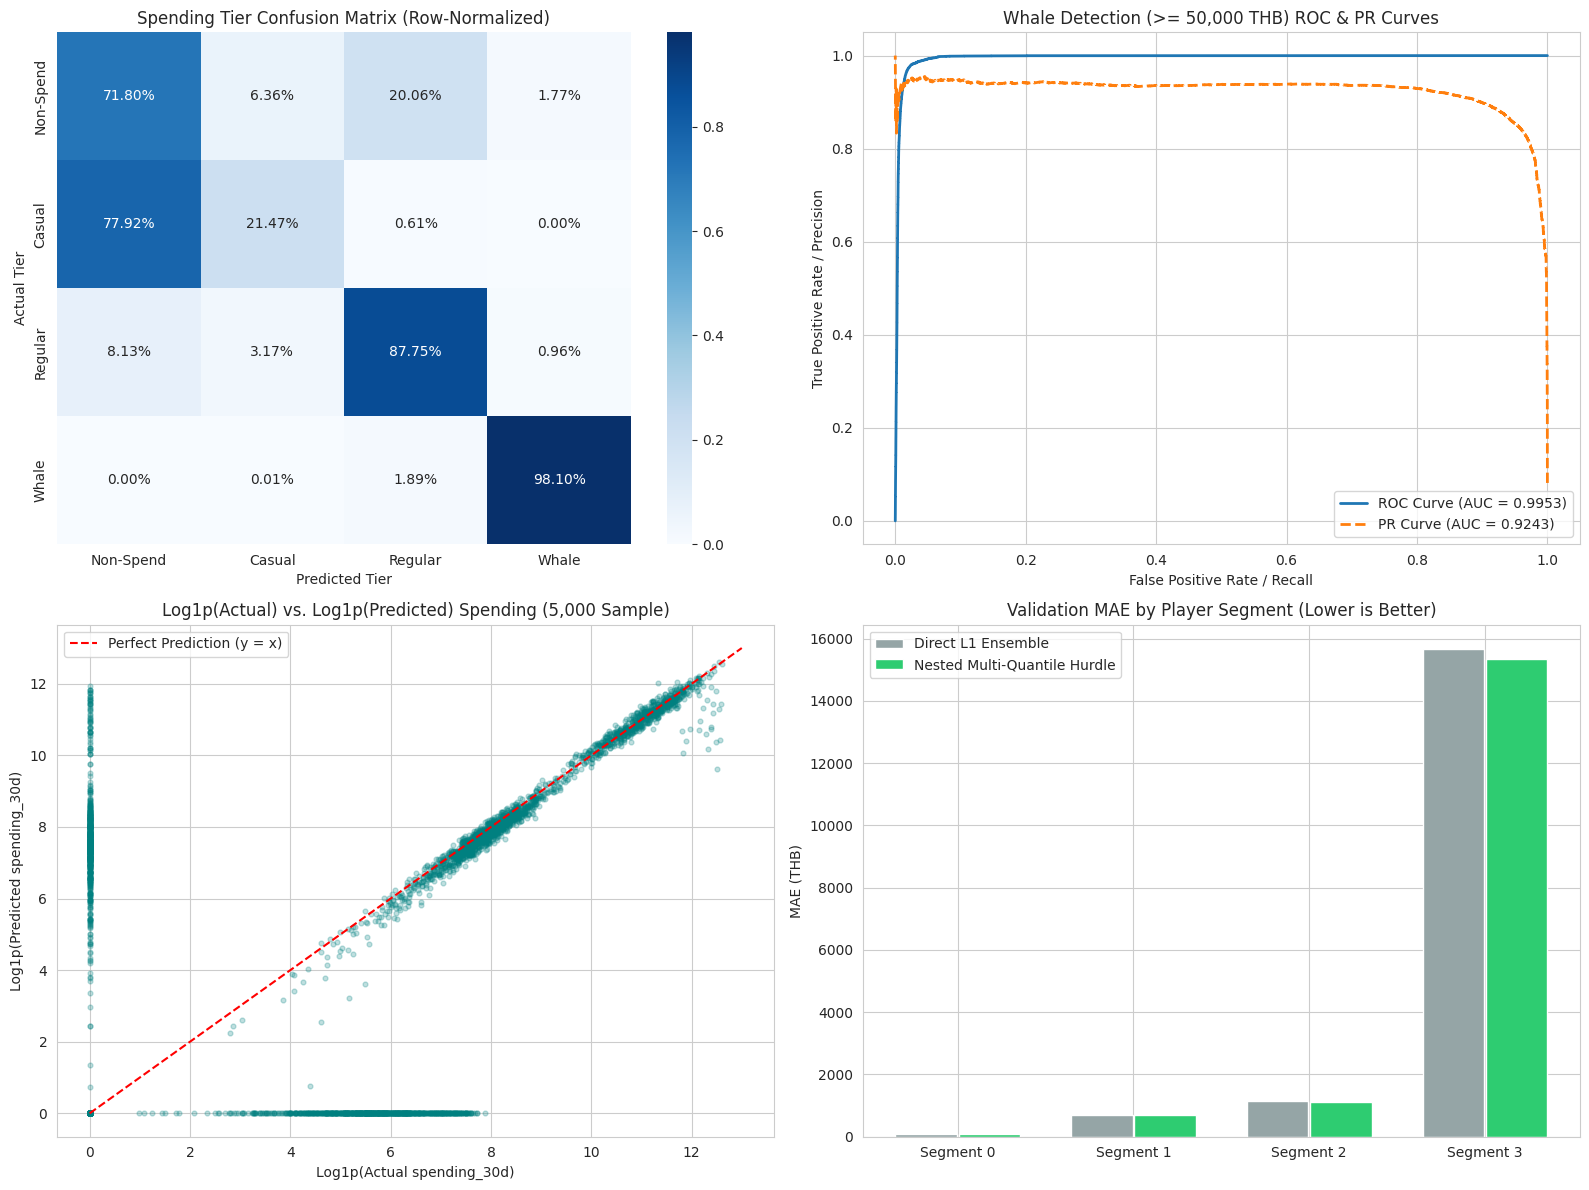

In [11]:
# ==============================================================================
# CELL 11: VALIDATION PART 4 — Visual Diagnostic Dashboard
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Panel 1: Normalized Confusion Matrix of 4 Spending Tiers
cm = confusion_matrix(y_true_tier, y_pred_tier, normalize='true')
sns.heatmap(
    cm, annot=True, fmt=".2%", cmap="Blues",
    xticklabels=["Non-Spend", "Casual", "Regular", "Whale"],
    yticklabels=["Non-Spend", "Casual", "Regular", "Whale"], ax=axes[0, 0]
)
axes[0, 0].set_title("Spending Tier Confusion Matrix (Row-Normalized)")
axes[0, 0].set_xlabel("Predicted Tier")
axes[0, 0].set_ylabel("Actual Tier")

# Panel 2: ROC & Precision-Recall Curves for Whale Detection (>= 50k THB)
fpr, tpr, _ = roc_curve(y_true_whale, oof_final)
prec_c, rec_c, _ = precision_recall_curve(y_true_whale, oof_final)
axes[0, 1].plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc_score(y_true_whale, oof_final):.4f})", lw=2)
axes[0, 1].plot(rec_c, prec_c, label=f"PR Curve (AUC = {average_precision_score(y_true_whale, oof_final):.4f})", lw=2, linestyle='--')
axes[0, 1].set_title("Whale Detection (>= 50,000 THB) ROC & PR Curves")
axes[0, 1].set_xlabel("False Positive Rate / Recall")
axes[0, 1].set_ylabel("True Positive Rate / Precision")
axes[0, 1].legend()

# Panel 3: Actual vs. Predicted Spending (Log1p Scale, Sampled)
sample_idx = np.random.choice(len(y), size=5000, replace=False)
axes[1, 0].scatter(np.log1p(y[sample_idx]), np.log1p(oof_final[sample_idx]), alpha=0.25, s=12, color='teal')
axes[1, 0].plot([0, 13], [0, 13], 'r--', lw=1.5, label="Perfect Prediction (y = x)")
axes[1, 0].set_title("Log1p(Actual) vs. Log1p(Predicted) Spending (5,000 Sample)")
axes[1, 0].set_xlabel("Log1p(Actual spending_30d)")
axes[1, 0].set_ylabel("Log1p(Predicted spending_30d)")
axes[1, 0].legend()

# Panel 4: MAE Reduction by Segment (Direct L1 vs. Nested Multi-Quantile Ensemble)
segs = [0, 1, 2, 3]
mae_dir_seg = [mean_absolute_error(y[train_fe['segment_imputed'] == s], oof_reg_all[train_fe['segment_imputed'] == s]) for s in segs]
mae_opt_seg = [mean_absolute_error(y[train_fe['segment_imputed'] == s], oof_final[train_fe['segment_imputed'] == s]) for s in segs]
x_pos = np.arange(len(segs))
axes[1, 1].bar(x_pos - 0.18, mae_dir_seg, width=0.35, label="Direct L1 Ensemble", color="#95a5a6")
axes[1, 1].bar(x_pos + 0.18, mae_opt_seg, width=0.35, label="Nested Multi-Quantile Hurdle", color="#2ecc71")
axes[1, 1].set_xticks(x_pos)
axes[1, 1].set_xticklabels([f"Segment {s}" for s in segs])
axes[1, 1].set_title("Validation MAE by Player Segment (Lower is Better)")
axes[1, 1].set_ylabel("MAE (THB)")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

In [12]:
# ==============================================================================
# CELL 12: Pre-Submission Integrity Audit & Export
# ==============================================================================
sub = pd.DataFrame({
    'player_id': test_df['player_id'],
    'spending_30d': np.round(test_final, 2)
})

# Hard sanity assertions
assert len(sub) == len(test_df), f"Expected {len(test_df)} rows, got {len(sub)}"
assert list(sub.columns) == ['player_id', 'spending_30d'], f"Invalid columns: {list(sub.columns)}"
assert (sub['player_id'].values == test_df['player_id'].values).all(), "player_id order mismatch!"
assert sub['spending_30d'].isna().sum() == 0, "Submission contains NaN!"
assert np.isinf(sub['spending_30d']).sum() == 0, "Submission contains Inf!"
assert (sub['spending_30d'] >= 0).all() and (sub['spending_30d'] <= 300000).all(), "Out of valid range [0, 300000]!"

# Compare OOF vs Test prediction distributions
dist_check = pd.DataFrame({
    "Train OOF Pred": pd.Series(oof_final).describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]),
    "Test Final Pred": sub['spending_30d'].describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99])
})
print("=== OOF VS. TEST DISTRIBUTION ALIGNMENT CHECK ===")
print(dist_check.round(2))

sub.to_csv("submission_task3_optimized.csv", index=False)
print("\nALL CHECKS PASSED! Saved optimized Task 3 predictions to 'submission_task3_optimized.csv'.")

=== OOF VS. TEST DISTRIBUTION ALIGNMENT CHECK ===
       Train OOF Pred  Test Final Pred
count       104000.00         25889.00
mean         10575.82         10484.88
std          28167.43         27815.38
min              0.00             0.00
50%            150.17           101.45
75%           2861.46          2829.94
90%          41546.02         41836.35
95%          75955.01         76075.13
99%         134972.92        134407.50
max         300000.00        300000.00

ALL CHECKS PASSED! Saved optimized Task 3 predictions to 'submission_task3_optimized.csv'.
